# Pandas - Topic 04 - Index and MultiIndex¶


## Topic Objectives

- Understand and manipulate indices in a pandas DataFrame


## Import Package for Learning

In [14]:
import numpy as np
import pandas as pd

## Index and MultiIndex¶

In this notebook we will cover:

- how to access a DataFrame index with .index
- how to set and reset a index with .set_index() and .reset_index(), respectively
- how to check an index name with .index.names
- how to differentiate between a one level index and Multilevel index DataFrame

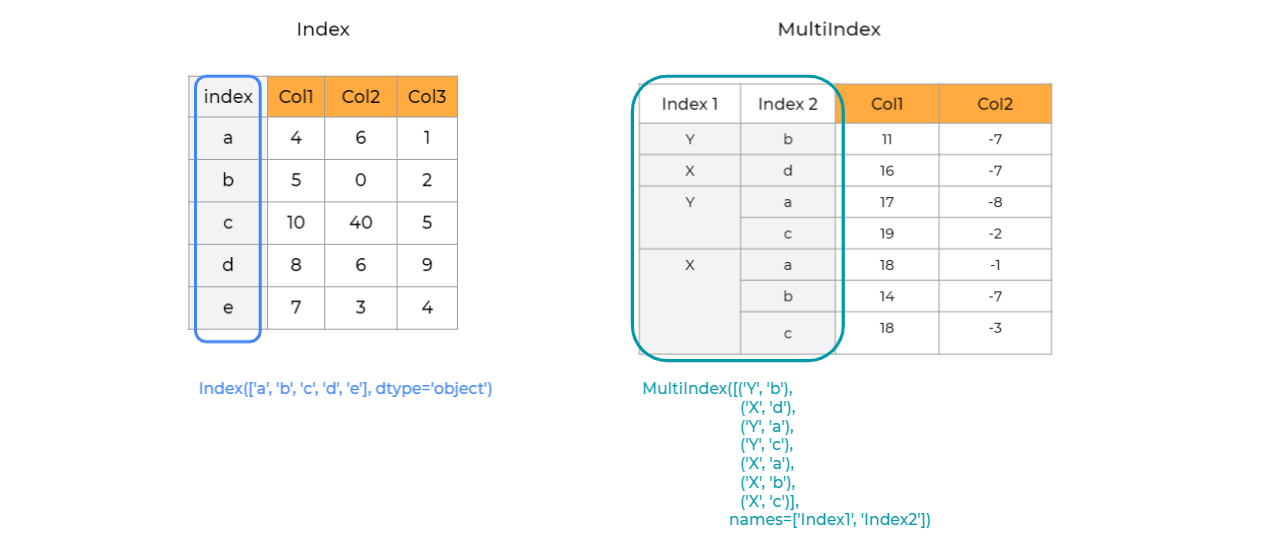

### Index

Let's consider the DataFrame below

In [15]:
np.random.seed(101)
df = pd.DataFrame(data=np.random.randn(5,4),
                  index=['A', 'B', 'C', 'D', 'E'],  
                  columns=['Col1', 'Col2', 'Col3', 'Col4']
                  )
df

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
C,-2.018168,0.740122,0.528813,-0.589001
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509


You can check index content with the method .index

In [16]:
df.index

Index(['A', 'B', 'C', 'D', 'E'], dtype='object')

You can reset your index label to integers starting from 0 using .reset_index()

- This example doesn't overwrite the DataFrame, since inplace is not set to True

In [17]:
df.reset_index()

,index,Col1,Col2,Col3,Col4
0,A,2.706850,0.628133,0.907969,0.503826
1,B,0.651118,-0.319318,-0.848077,0.605965
2,C,-2.018168,0.740122,0.528813,-0.589001
3,D,0.188695,-0.758872,-0.933237,0.955057
4,E,0.190794,1.978757,2.605967,0.683509


You will notice that the index would become an additional column in the DataFrame.

- If you are not interested in keeping the index column, you can set drop=True
- The example above doesn't overwrite the DataFrame.


The example below overwrites the DataFrame since it includes inplace=True (a parameter you are familiar with already)

- You can check the DataFrame content and note that the labels A, B, C, D, E are not indices.
- It is now a range of integers starting from 0. In addition, the labels A, B, C, D, E no longer exist

In [18]:
df.reset_index(drop=True, inplace=True)
df

,Col1,Col2,Col3,Col4
0,2.706850,0.628133,0.907969,0.503826
1,0.651118,-0.319318,-0.848077,0.605965
2,-2.018168,0.740122,0.528813,-0.589001
3,0.188695,-0.758872,-0.933237,0.955057
4,0.190794,1.978757,2.605967,0.683509


Let's add a column based on a list. The list content is generic.

In [19]:
df['Col5'] = ['Part1','Part2','Part3', 'Item1','Item2']
df

,Col1,Col2,Col3,Col4,Col5
0,2.706850,0.628133,0.907969,0.503826,Part1
1,0.651118,-0.319318,-0.848077,0.605965,Part2
2,-2.018168,0.740122,0.528813,-0.589001,Part3
3,0.188695,-0.758872,-0.933237,0.955057,Item1
4,0.190794,1.978757,2.605967,0.683509,Item2


Let's set Col5 as index with .set_index() and inplace=True

In [20]:
df.set_index('Col5',inplace=True)
df

,Col1,Col2,Col3,Col4
Col5,,,,
Part1,2.706850,0.628133,0.907969,0.503826
Part2,0.651118,-0.319318,-0.848077,0.605965
Part3,-2.018168,0.740122,0.528813,-0.589001
Item1,0.188695,-0.758872,-0.933237,0.955057
Item2,0.190794,1.978757,2.605967,0.683509


### MultiIndex¶

Your DataFrame can have MultiIndex

- First, consider the following DataFrame .

In [21]:
np.random.seed(101)
df = pd.DataFrame(data=np.random.randn(5,4),
                  index=['A', 'B', 'C', 'D', 'E'],  
                  columns=['Col1', 'Col2', 'Col3', 'Col4']
                  )
df

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
C,-2.018168,0.740122,0.528813,-0.589001
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509


We will check the index with df.index.

- You will notice there is only one level

In [22]:
df.index

Index(['A', 'B', 'C', 'D', 'E'], dtype='object')

Now consider the DataFrame below made with NumPy functions you are already familiar with.

In [23]:
np.random.seed(seed=13)
df = pd.DataFrame(data={'Col1':np.random.randint(low=10, high=20, size=10),
                        'Col2':np.random.randint(low=-10, high=0, size=10),
                        'Category1': np.random.choice(['X','Y','Z'], size=10),
                        'Category2': np.random.choice(['a','b','c','d','e','f','g'], size=10)}
                  )

df

,Col1,Col2,Category1,Category2
0,12,-4,Y,e
1,10,-5,Y,f
2,10,-1,Z,d
3,16,-6,X,f
4,12,-8,X,a
5,14,-10,X,d
6,19,-7,X,c
7,13,-5,Z,a
8,14,-7,Z,f
9,12,-4,Z,b


We will set Category1 and Category2 as Index with .set_index().

- Let's see the effect of it.
  - Note there are 2 levels of the index when you hover the mouse over the index area

In [24]:
df.set_index(['Category1','Category2'], inplace=True)
df

Col1  Col2
Category1 Category2            
Y         e            12    -4
          f            10    -5
Z         d            10    -1
X         f            16    -6
          a            12    -8
          d            14   -10
          c            19    -7
Z         a            13    -5
          f            14    -7
          b            12    -4

Now we check the index content and see mention of MultiIndex, and the respective pairs of Category1 and Category2 that together create this MultiIndex structure

In [25]:
df.index

MultiIndex([('Y', 'e'),
            ('Y', 'f'),
            ('Z', 'd'),
            ('X', 'f'),
            ('X', 'a'),
            ('X', 'd'),
            ('X', 'c'),
            ('Z', 'a'),
            ('Z', 'f'),
            ('Z', 'b')],
           names=['Category1', 'Category2'])

We can grab the index names with .index.names

In [26]:
df.index.names

FrozenList(['Category1', 'Category2'])

The MultIindex format will likely appear over your career in the workplace.

- Typically, we tend to prefer a DataFrame that is not MultiIndexed, since the majority of the data science packages have functions/methods more suitable for non MultiIndex DataFrames.
- In this case, you can remove the hierarchical index by adding .reset_index()

In [27]:
df.reset_index(inplace=True)
df

,Category1,Category2,Col1,Col2
0,Y,e,12,-4
1,Y,f,10,-5
2,Z,d,10,-1
3,X,f,16,-6
4,X,a,12,-8
5,X,d,14,-10
6,X,c,19,-7
7,Z,a,13,-5
8,Z,f,14,-7
9,Z,b,12,-4
